# Module 9 · Queueing systems and discrete-event simulation
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **How much service capacity keeps a hypothetical bike-maintenance queue from growing?**

Guided work: about 45–55 minutes. Exercises: about 25–35 minutes. This is **Concept Lab 5, Part A (week 9)**. Combine with Module 10, Part B, in **one submission due in week 10**. The existing project **model/validation checkpoint remains due in week 9**.

[Course home](../index.html) · [Interactive lesson](../modules/module09.html) · [Project guide](../project-guide.html)

We first model a synthetic queue and test an event-driven simulator against an independent recursion and exact theory. The bike data later supply an observed volume scale for a deliberately assumed maintenance scenario. They do not contain observed maintenance arrivals, service times, or waits.

## 1. State the queue before simulating it
We assume one server, a first-come-first-served (FCFS) discipline, an infinite waiting room, no abandonment, and service independent of arrivals. The server starts empty at time zero. Arrivals $A_i$ are ordered, services $S_i>0$, service starts are $C_i$, and departures are $D_i$.

$$C_i=\max(A_i,D_{i-1}),\quad D_i=C_i+S_i,\quad W_{q,i}=C_i-A_i,\quad W_i=D_i-A_i.$$

Take $D_0=0$. **Waiting time** $W_q$ excludes service; **system time** $W$ includes it. Rates $\lambda$ and $\mu$ have units jobs/hour; service mean is $1/\mu$ hours/job. In an M/M/1 queue, arrivals are Poisson and service is exponential. M/D/1 uses the same Poisson arrivals but fixed service. A waiting queue differs from Module 8's finite inventory model: customers here wait instead of being blocked at a boundary.

Before running code: at $\lambda=2$, would changing $\mu$ from 3 to 4 merely halve waiting? Predict the effect of fixed service with the same mean.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
SEED, REPLICAS, BURN, KEEP = 6231, 40, 1000, 10000
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

In [2]:
def check_cohort(arrivals, services):
    a, s = np.asarray(arrivals, float), np.asarray(services, float)
    if a.ndim != 1 or s.shape != a.shape or len(a) == 0:
        raise ValueError("Use equal nonempty one-dimensional arrays")
    if not np.isfinite(a).all() or not np.isfinite(s).all():
        raise ValueError("All inputs must be finite")
    if a[0] < 0 or np.any(np.diff(a) < 0) or np.any(s <= 0):
        raise ValueError("Arrivals must be ordered and nonnegative; service positive")
    return a, s

In [3]:
def after_departure(j, i, time, services, starts):
    if j < i:
        starts[j] = time
        return time + services[j]
    return np.inf

def after_arrival(i, j, time, services, starts, next_departure):
    if i == j:
        starts[i] = time
        return time + services[i]
    return next_departure

### Advance to the next event
The event calendar stores the next arrival and the next departure. An idle server has next departure $+\infty$. At each step process the earlier event; at a tie process a departure first. A waiting customer starts service immediately after a departure. Advance the clock directly between events; a small time step is unnecessary.

We pre-generate the arrival and service arrays so an independent Lindley recursion can use exactly the same inputs. The finite cohort stops admitting customers after its last scheduled arrival and **drains completely**. The drain is an observation convention, not abandonment or an extra arrival.

In [4]:
def event_calendar(arrivals, services):
    a, s = check_cohort(arrivals, services)
    n = len(a)
    starts, departures = np.zeros(n), np.zeros(n)
    i, j, next_departure = 0, 0, np.inf
    while j < n:
        next_arrival = a[i] if i < n else np.inf
        if next_departure <= next_arrival:
            departures[j] = next_departure
            j += 1
            next_departure = after_departure(j, i, next_departure, s, starts)
        else:
            next_departure = after_arrival(i, j, next_arrival, s, starts, next_departure)
            i += 1
    return starts, departures

In [5]:
def lindley(arrivals, services):
    a, s = check_cohort(arrivals, services)
    starts, departures = np.zeros(len(a)), np.zeros(len(a))
    previous = 0.0
    for k in range(len(a)):
        starts[k] = max(a[k], previous)
        departures[k] = starts[k] + s[k]
        previous = departures[k]
    return starts, departures

def occupation(arrivals, departures):
    times = np.r_[0.0, departures, arrivals]  # Departures precede arrivals at ties.
    change = np.r_[0, -np.ones(len(departures)), np.ones(len(arrivals))]
    order = np.argsort(times, kind="stable")
    return times[order], np.cumsum(change[order])

In [6]:
def cohort_summary(arrivals, services):
    starts, departures = event_calendar(arrivals, services)
    waits, systems = starts - arrivals, departures - arrivals
    times, numbers = occupation(arrivals, departures)
    intervals = np.diff(times)
    area_n = np.dot(numbers[:-1], intervals)
    area_q = np.dot(np.maximum(numbers[:-1] - 1, 0), intervals)
    horizon, n = departures[-1], len(arrivals)
    assert np.allclose([area_q, area_n], [waits.sum(), systems.sum()])
    return dict(wait=waits, system=systems, starts=starts, departures=departures,
                time=times, number=numbers, area_q=area_q, area_n=area_n,
                horizon=horizon, throughput=n/horizon)

In [7]:
def draw_cohort(lam, mu, n, rng, arrival="Poisson", service="Exponential"):
    if lam <= 0 or mu <= 0 or n < 1:
        raise ValueError("Use positive rates and a positive cohort size")
    if arrival not in ("Poisson", "Bursty") or service not in ("Exponential", "Fixed"):
        raise ValueError("Choose one of the displayed arrival and service laws")
    gap_scale = np.ones(n) / lam
    if arrival == "Bursty":
        gap_scale *= rng.choice([0.5, 1.5], size=n)
    gaps = rng.exponential(gap_scale)
    services = rng.exponential(1/mu, n) if service == "Exponential" else np.full(n, 1/mu)
    return np.cumsum(gaps), services

In [8]:
a_demo = np.array([0.0, 0.5, 3.0])
s_demo = np.array([1.0, 1.0, 1.0])
demo = cohort_summary(a_demo, s_demo)
assert np.allclose(event_calendar(a_demo, s_demo), lindley(a_demo, s_demo))
display(pd.DataFrame({"arrival": a_demo, "service": s_demo,
    "start": demo["starts"], "departure": demo["departures"],
    "waiting": demo["wait"], "system": demo["system"]}))
print("Queue area, system area, drain horizon:", demo["area_q"], demo["area_n"], demo["horizon"])

,arrival,service,start,departure,waiting,system
0,0.0,1.0,0.0,1.0,0.0,1.0
1,0.5,1.0,1.0,2.0,0.5,1.5
2,3.0,1.0,3.0,4.0,0.0,1.0


Queue area, system area, drain horizon: 0.5 3.5 4.0


## 2. Little's law: match the population and the window
Let $N(t)$ count customers in the system and $Q(t)=\max(N(t)-1,0)$ count customers waiting. For all $n$ admitted customers, from time zero to the final departure $H$, the identities are exact:

$$\int_0^H Q(t)\,dt=\sum_{i=1}^n W_{q,i},\qquad
\int_0^H N(t)\,dt=\sum_{i=1}^n W_i.$$

Hence $L_q^{(H)}=(n/H)\overline W_q$ and $L^{(H)}=(n/H)\overline W$. Use **realized throughput** $n/H$, not the input rate $\lambda$, in this finite identity. Idle time before the first arrival belongs to the same horizon. The stable stationary relation $L=\lambda E[W]$ is a limiting statement with finite relevant means.

Do not combine a full-path occupation integral with a post-warmup customer mean. For a fixed calendar window containing incomplete customers, use their clipped occupancy contributions; censoring cannot be silently ignored.

Finite full-path Lq and L: [5.5026971  6.40117632]


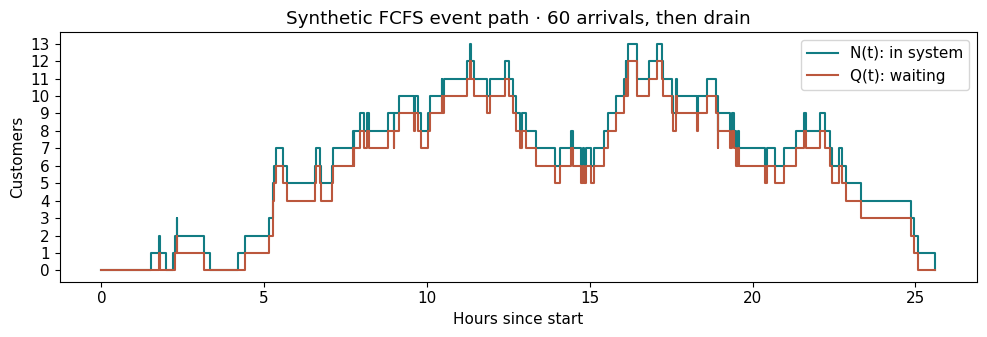

In [9]:
path_a, path_s = draw_cohort(2, 3, 60, np.random.default_rng(SEED))
path = cohort_summary(path_a, path_s)
assert np.allclose(event_calendar(path_a, path_s), lindley(path_a, path_s))
assert np.all(path["starts"] >= path_a) and np.all(path["number"] >= 0)
assert path["number"][-1] == 0
finite_little = np.array([path["area_q"], path["area_n"]])/path["horizon"]
assert np.allclose(finite_little, path["throughput"]*np.array([path["wait"].mean(), path["system"].mean()]))
print("Finite full-path Lq and L:", finite_little)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.step(path["time"], path["number"], where="post", color="#117c83", label="N(t): in system")
ax.step(path["time"], np.maximum(path["number"]-1, 0), where="post", color="#bb573d", label="Q(t): waiting")
ax.set(xlabel="Hours since start", ylabel="Customers", title="Synthetic FCFS event path · 60 arrivals, then drain")
ax.set_yticks(range(int(max(path["number"]))+1)); ax.legend(); fig.tight_layout(); plt.show()

## 3. Exact benchmarks require their assumptions
With Poisson arrival rate $\lambda$, iid independent service $S$, and utilization $\rho=\lambda E[S]<1$, the M/G/1 Pollaczek–Khinchine formula is

$$E[W_q]=\frac{\lambda E[S^2]}{2(1-\rho)},\qquad E[W]=E[W_q]+E[S].$$

For M/M/1, $E[S^2]=2/\mu^2$ and $E[W_q]=\lambda/[\mu(\mu-\lambda)]$, while $E[W]=1/(\mu-\lambda)$. At $(\lambda,\mu)=(2,3)$ this gives $E[W_q]=2/3$ hour, $E[W]=1$ hour, $L_q=4/3$, and $L=2$. M/D/1 has $E[S^2]=1/\mu^2$, giving $E[W_q]=1/3$ and $E[W]=2/3$ hour. Lower service variance reduces waiting here.

These exact expressions describe **steady state**. Starting empty creates an initial transient. The finite experiment discards the first $B$ customer records, then averages the next $N$ fully served customers; all customers remain in the event simulation. This is a customer-cohort estimator, not a calendar-window time average.

For $R$ independent replications with cohort means $\bar W_{q,r}$, report
$$\widehat w_q=\frac1R\sum_r\bar W_{q,r},\qquad
\operatorname{MCSE}(\widehat w_q)=\frac{s(\bar W_{q,1},\ldots,\bar W_{q,R})}{\sqrt R}.$$
Within a queue, consecutive waits are dependent. Their iid standard error is generally wrong. Replica MCSE measures Monte Carlo variation, **not initialization bias or model error**. A warmup sensitivity check is evidence, not proof that a chosen $B$ is sufficient.

In [10]:
def replica_means(lam, mu, arrival="Poisson", service="Exponential",
                  burn=BURN, keep=KEEP, replicas=REPLICAS, seed=SEED):
    if burn < 0 or keep < 1 or replicas < 2:
        raise ValueError("Use burn >= 0, keep >= 1, and at least two replicas")
    rows = []
    for child in np.random.SeedSequence(seed).spawn(replicas):
        a, s = draw_cohort(lam, mu, burn + keep, np.random.default_rng(child), arrival, service)
        starts, departures = event_calendar(a, s)
        rows.append([(starts[burn:] - a[burn:]).mean(),
                     (departures[burn:] - a[burn:]).mean()])
    return np.asarray(rows)

def mean_mcse(values):
    return np.mean(values, axis=0), np.std(values, axis=0, ddof=1)/np.sqrt(len(values))

In [11]:
def exact_poisson(lam, mu, service="Exponential"):
    rho = lam/mu
    if rho >= 1:
        return dict(rho=rho, Wq=np.nan, W=np.nan, Lq=np.nan, L=np.nan)
    second_moment = (2 if service == "Exponential" else 1)/mu**2
    wq = lam*second_moment/(2*(1-rho))
    return dict(rho=rho, Wq=wq, W=wq+1/mu, Lq=lam*wq, L=lam*(wq+1/mu))

def result_row(label, values):
    avg, se = mean_mcse(values)
    return dict(scenario=label, Wq_hours=avg[0], Wq_MCSE=se[0],
                W_hours=avg[1], W_MCSE=se[1])

In [12]:
baseline = {}
for service in ["Exponential", "Fixed"]:
    baseline[service] = replica_means(2, 3, service=service)
benchmark_rows = []
for service, values in baseline.items():
    row = result_row(service, values)
    theory = exact_poisson(2, 3, service)
    row.update(exact_Wq=theory["Wq"], exact_W=theory["W"])
    row.update(Wq_error=row["Wq_hours"]-theory["Wq"], W_error=row["W_hours"]-theory["W"])
    benchmark_rows.append(row)
benchmark = pd.DataFrame(benchmark_rows)
display(benchmark)
print(f"Independent replicas: {REPLICAS}; discarded customers: {BURN}; measured customers: {KEEP}")

,scenario,Wq_hours,Wq_MCSE,W_hours,W_MCSE,exact_Wq,exact_W,Wq_error,W_error
0,Exponential,0.675981,0.008375,1.009640,0.008762,0.666667,1.000000,0.009314,0.009640
1,Fixed,0.334675,0.002614,0.668009,0.002614,0.333333,0.666667,0.001342,0.001342


Independent replicas: 40; discarded customers: 1000; measured customers: 10000


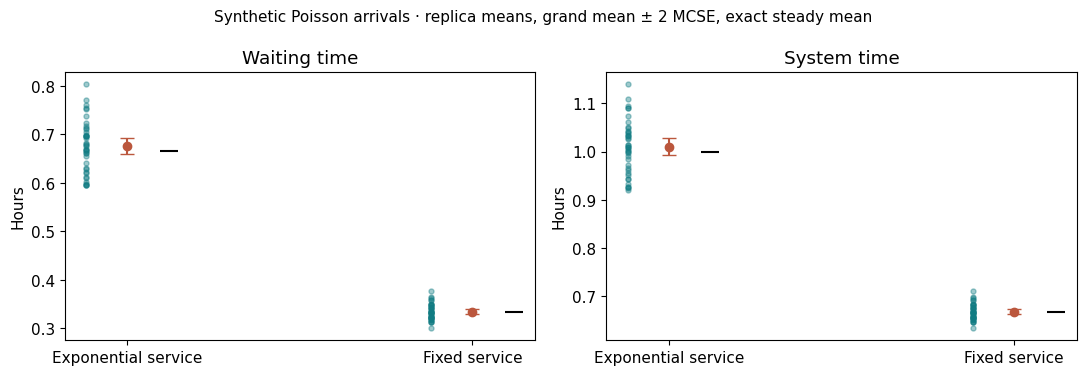

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric, exact_key in zip(axes, [0, 1], ["Wq", "W"]):
    for j, (service, values) in enumerate(baseline.items()):
        avg, se = mean_mcse(values)
        ax.scatter(np.full(REPLICAS, j)-0.12, values[:, metric], s=13, alpha=0.4, color="#117c83")
        ax.errorbar(j, avg[metric], yerr=2*se[metric], fmt="o", capsize=5, color="#bb573d")
        ax.scatter(j+0.12, exact_poisson(2, 3, service)[exact_key], marker="_", s=150, color="black")
    ax.set(xticks=[0, 1], xticklabels=["Exponential service", "Fixed service"], ylabel="Hours")
    ax.set_title("Waiting time" if metric == 0 else "System time")
fig.suptitle("Synthetic Poisson arrivals · replica means, grand mean ± 2 MCSE, exact steady mean", fontsize=11)
fig.tight_layout(); plt.show()

## 4. Vary capacity and arrival variability
For bursty arrivals, each iid gap is drawn from an equal mixture of exponential distributions with means $0.5/\lambda$ and $1.5/\lambda$. Its mean remains $1/\lambda$, but its squared coefficient of variation is $C_a^2=1.5$ (Poisson gaps have $C_a^2=1$). This is a renewal arrival process, **not a Poisson process with a changing calendar-time rate**. All service times are independent of gaps.

The stability criterion for these iid GI/GI/1 scenarios is $\rho<1$. The M/M/1 and M/G/1 formulas above cease to be exact when arrivals use the bursty renewal law. Use simulation with independent replications for that case. Increasing $\mu$ changes mean service capacity, and keeping $\mu$ fixed while changing gap variability isolates a different mechanism.

,scenario,Wq_hours,Wq_MCSE,W_hours,W_MCSE,arrival,mu,exact_Wq
0,"Poisson, mu=3",0.675981,0.008375,1.009640,0.008762,Poisson,3.0,0.666667
1,"Poisson, mu=4",0.253522,0.002219,0.503766,0.002523,Poisson,4.0,0.250000
2,"Bursty, mu=3",0.857155,0.011419,1.190927,0.011729,Bursty,3.0,NaN
3,"Bursty, mu=4",0.325988,0.003301,0.576317,0.003566,Bursty,4.0,NaN


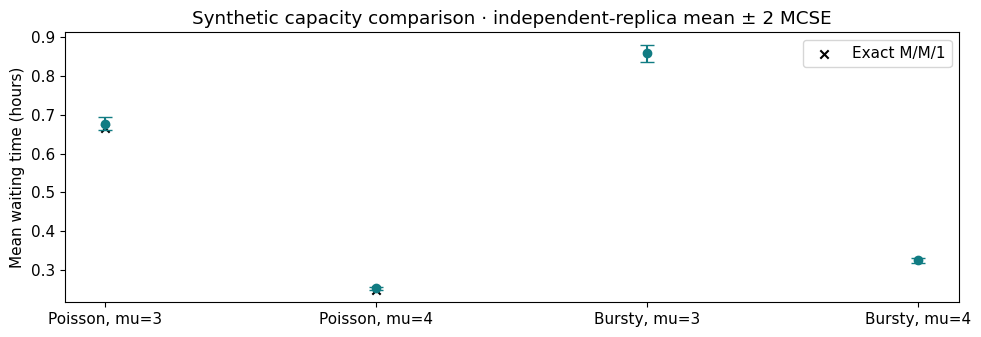

In [14]:
capacity_rows = []
for arrival in ["Poisson", "Bursty"]:
    for mu in [3.0, 4.0]:
        values = baseline["Exponential"] if (arrival, mu) == ("Poisson", 3) else replica_means(2, mu, arrival=arrival)
        row = result_row(f"{arrival}, mu={mu:g}", values)
        row.update(arrival=arrival, mu=mu, exact_Wq=exact_poisson(2, mu)["Wq"] if arrival == "Poisson" else np.nan)
        capacity_rows.append(row)
capacity = pd.DataFrame(capacity_rows)
display(capacity)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.errorbar(range(4), capacity.Wq_hours, yerr=2*capacity.Wq_MCSE, fmt="o", capsize=5, color="#117c83")
ax.scatter(range(2), capacity.exact_Wq[:2], marker="x", color="black", label="Exact M/M/1")
ax.set(xticks=range(4), xticklabels=capacity.scenario, ylabel="Mean waiting time (hours)",
       title="Synthetic capacity comparison · independent-replica mean ± 2 MCSE")
ax.legend(); fig.tight_layout(); plt.show()

### Finite completion does not establish stability
If $\lambda\ge\mu$, the assumed queue has no finite stationary mean waiting time. A finite arrival list still drains because arrivals stop and every service is finite. Its eventual empty state says nothing about a perpetually operating overloaded system.

The next comparison starts empty with no warmup, holds $\lambda=4$, $\mu=3$, and lengthens the measured cohort. At $\lambda>\mu$, waiting typically grows with customer index. At equality there is also no finite stationary mean for these stochastic scenarios; zero drift does not imply a stable queue.

,scenario,Wq_hours,Wq_MCSE,W_hours,W_MCSE,N
0,N=1000,42.491293,1.218412,42.823699,1.219629,1000
1,N=5000,209.160073,2.915469,209.493258,2.916188,5000


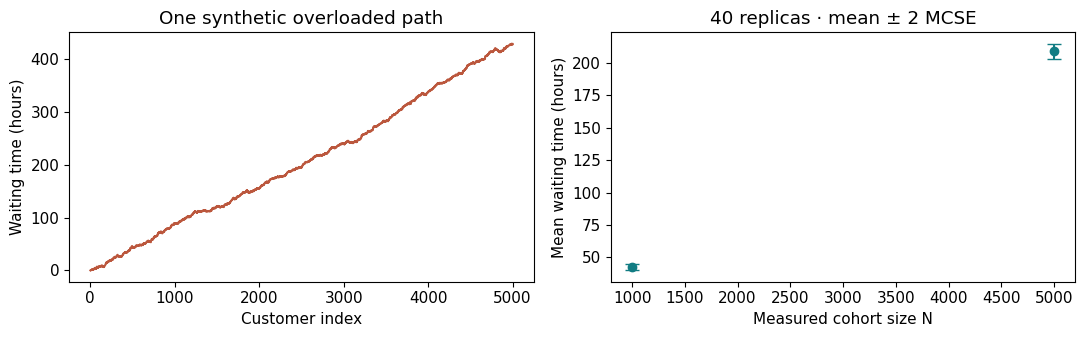

In [15]:
overload_rows = []
for size in [1000, 5000]:
    values = replica_means(4, 3, burn=0, keep=size)
    row = result_row(f"N={size}", values); row["N"] = size
    overload_rows.append(row)
overload = pd.DataFrame(overload_rows)
display(overload)
a_over, s_over = draw_cohort(4, 3, 5000, np.random.default_rng(SEED+1))
start_over, _ = event_calendar(a_over, s_over)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(np.arange(1, 5001), start_over-a_over, color="#bb573d")
axes[0].set(xlabel="Customer index", ylabel="Waiting time (hours)", title="One synthetic overloaded path")
axes[1].errorbar(overload.N, overload.Wq_hours, yerr=2*overload.Wq_MCSE, fmt="o", capsize=5, color="#117c83")
axes[1].set(xlabel="Measured cohort size N", ylabel="Mean waiting time (hours)", title="40 replicas · mean ± 2 MCSE")
fig.tight_layout(); plt.show()

## 5. Use observed bike volume without inventing a queue dataset
The unchanged UCI Bike Sharing sample contains **365 daily system-wide completed-rental totals in 2011**. Source: Hadi Fanaee-T (2013), [UCI Bike Sharing](https://doi.org/10.24432/C5W894), CC BY 4.0. Verify its saved checksum and complete calendar before analysis.

January–August supplies the training-period volume scale. September–December is only a descriptive comparison; it has been repeatedly inspected in earlier modules and is not a fresh validation set. Neither block observes maintenance referrals, attempted rentals, service durations, stations, servers, waiting, or abandonment. A rental total is not an arrival record for a maintenance queue.

In [16]:
candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next(p for p in candidates if (p/"data/bike_daily_2011.csv").is_file())
data_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT/"data/source_metadata.json").read_text())
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(data_path, parse_dates=["dteday"])
assert bike.dteday.tolist() == list(pd.date_range("2011-01-01", "2011-12-31"))
assert len(bike) == 365 and bike.cnt.ge(0).all() and bike.dteday.is_unique
training = bike[bike.dteday < "2011-09-01"]
later = bike[bike.dteday >= "2011-09-01"]
volume = pd.DataFrame({name: {"days": len(d), "total": d.cnt.sum(),
    "mean_per_day": d.cnt.mean(), "zero_days": d.cnt.eq(0).sum()}
    for name, d in [("Jan–Aug training", training), ("Sep–Dec descriptive", later)]}).T
assert training.cnt.sum() == 802684 and later.cnt.sum() == 440419
display(volume)

,days,total,mean_per_day,zero_days
Jan–Aug training,243.0,802684.0,3303.226337,0.0
Sep–Dec descriptive,122.0,440419.0,3609.991803,0.0


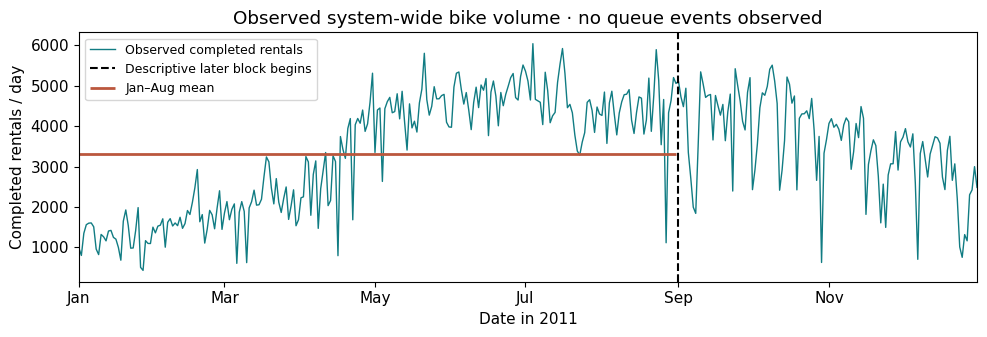

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(bike.dteday, bike.cnt, linewidth=1, color="#117c83", label="Observed completed rentals")
ax.axvline(pd.Timestamp("2011-09-01"), color="black", linestyle="--", label="Descriptive later block begins")
ax.hlines(training.cnt.mean(), training.dteday.min(), training.dteday.max(), color="#bb573d", linewidth=2, label="Jan–Aug mean")
ax.set(xlabel="Date in 2011", ylabel="Completed rentals / day", title="Observed system-wide bike volume · no queue events observed", xlim=(bike.dteday.min(), bike.dteday.max()))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(fontsize=9); fig.tight_layout(); plt.show()

### An explicit maintenance scenario, not fitted arrival or service rates
Assume a fraction $p$ of completed rentals generates one maintenance job and all such work is spread over eight operating hours/day. Define
$$\lambda_{\mathrm{proxy}}=\frac{p\times\text{training mean completed rentals/day}}{8\ \text{hours/day}}.$$

At $p=0.005$, this gives about 2.0645 hypothetical jobs/hour. Assume one server with exponential service at $\mu=3$ or $4$ jobs/hour and additionally assume homogeneous Poisson referrals. These assumptions permit an M/M/1 **scenario calculation**; they are not inferred from the daily totals. Referral fraction, operating hours, pooling, arrival law, and service law are all unmeasured here. The modeled clock is continuous operating time; overnight carryover and closures are ignored and would require another model.

The sensitivity table labels $\lambda_{\mathrm{proxy}}\ge\mu$ as having no stationary mean; a negative value from blindly extending $1/(\mu-\lambda)$ would be meaningless. To validate a real maintenance queue, obtain referral arrival times, service starts/completions, queue discipline, server calendars/capacity, routing, observation windows, outages, and any losses or abandonment.

In [18]:
proxy_rows = []
for fraction in [0.0025, 0.005, 0.01]:
    lam_proxy = fraction * training.cnt.mean() / 8
    for mu_proxy in [3.0, 4.0]:
        values = exact_poisson(lam_proxy, mu_proxy)
        proxy_rows.append(dict(referral_fraction=fraction, lambda_proxy=lam_proxy,
            assumed_mu=mu_proxy, rho=values["rho"], Wq_hours=values["Wq"],
            status="stable assumed M/M/1" if values["rho"] < 1 else "no stationary mean"))
proxy_table = pd.DataFrame(proxy_rows)
display(proxy_table)
print("Default synthetic arrival proxy:", 0.005 * training.cnt.mean()/8, "jobs/hour")

,referral_fraction,lambda_proxy,assumed_mu,rho,Wq_hours,status
0,0.0025,1.032258,3.0,0.344086,0.174863,stable assumed M/M/1
1,0.0025,1.032258,4.0,0.258065,0.086957,stable assumed M/M/1
2,0.0050,2.064516,3.0,0.688172,0.735633,stable assumed M/M/1
3,0.0050,2.064516,4.0,0.516129,0.266667,stable assumed M/M/1
4,0.0100,4.129033,3.0,1.376344,NaN,no stationary mean
5,0.0100,4.129033,4.0,1.032258,NaN,no stationary mean


Default synthetic arrival proxy: 2.0645164609053497 jobs/hour


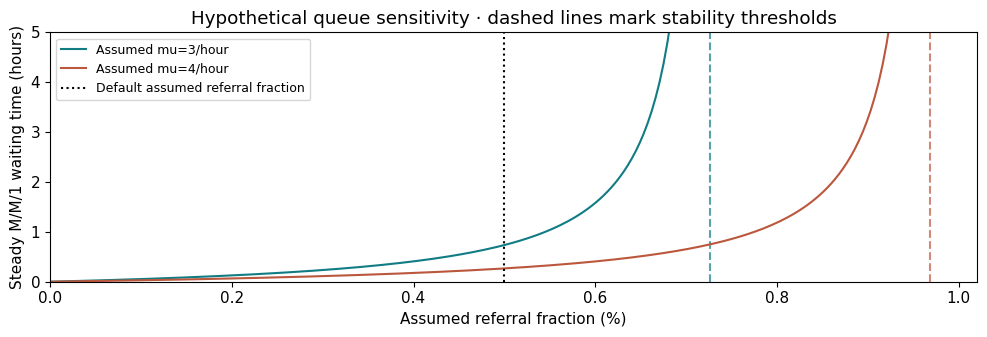

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for mu, color in [(3.0, "#117c83"), (4.0, "#bb573d")]:
    fractions = np.linspace(0, 0.0096, 220)
    arrival_proxy = fractions * training.cnt.mean()/8
    stable = arrival_proxy < mu
    waits = arrival_proxy[stable]/(mu*(mu-arrival_proxy[stable]))
    ax.plot(100*fractions[stable], waits, color=color, label=f"Assumed mu={mu:g}/hour")
    threshold = 100*8*mu/training.cnt.mean()
    ax.axvline(threshold, color=color, linestyle="--", alpha=0.7)
ax.axvline(0.5, color="black", linestyle=":", label="Default assumed referral fraction")
ax.set(xlabel="Assumed referral fraction (%)", ylabel="Steady M/M/1 waiting time (hours)", ylim=(0, 5),
       xlim=(0, 1.02), title="Hypothetical queue sensitivity · dashed lines mark stability thresholds")
ax.legend(fontsize=9); fig.tight_layout(); plt.show()

## 6. Verify before interpreting
Verification asks whether code implements its stated queue; validation asks whether that queue adequately represents the application. Agreement with M/M/1 theory is a software/model benchmark, not evidence that bike-maintenance referrals are Poisson.

Use at least two checks that can fail for different reasons: an independent event-calendar/Lindley comparison; full-path occupation identities; analytical steady benchmarks with Monte Carlo error; and a units/observation audit. Check nonnegative waits, positive services, ordered departures, and complete draining. An exact finite identity is stronger than a visual resemblance, but can still miss a shared error if both sides use the same wrong arrays.

**Repair these four flawed AI-style claims.** AI use is optional; no API or paid tool is needed. You may diagnose them directly. If you use an assistant, record the prompt and verify every retained correction.
```python
service = rng.exponential(mu)
Wq = 1 / (mu - lam)
se = waits.std(ddof=1) / np.sqrt(len(waits))
observed_mu = bike['cnt'].mean() / 24
```
State the units, assumptions, and correct target for each line. Do not merely replace syntax.

In [20]:
rng_check = np.random.default_rng(SEED+9)
a_check, s_check = draw_cohort(2, 3, 200, rng_check)
check = cohort_summary(a_check, s_check)
assert np.allclose(event_calendar(a_check, s_check), lindley(a_check, s_check))
assert np.all(check["wait"] >= 0) and np.all(np.diff(check["departures"]) > 0)
assert np.allclose(check["system"]-check["wait"], s_check)
a_replay, s_replay = draw_cohort(2, 3, 200, np.random.default_rng(SEED+9))
assert np.array_equal(a_check, a_replay) and np.array_equal(s_check, s_replay)
assert np.allclose(list(exact_poisson(2, 3).values()), [2/3, 2/3, 1, 4/3, 2])
assert np.isclose(exact_poisson(2, 3, "Fixed")["Wq"], 1/3)
assert np.isnan(exact_poisson(3, 3)["Wq"]) and np.isnan(exact_poisson(4, 3)["Wq"])
print("PASS: event recursion, legal paths, finite Little identities, exact formulas, and stability guards")
print("Runtime:", platform.python_version(), {p: metadata.version(p) for p in ["numpy", "pandas", "matplotlib"]})

PASS: event recursion, legal paths, finite Little identities, exact formulas, and stability guards
Runtime: 3.10.9 {'numpy': '1.24.2', 'pandas': '2.0.0', 'matplotlib': '3.7.1'}


## 7. Four short investigations · leave your work here
Keep this as Part A of one Concept Lab 5 submission, combined with Module 10 in week 10. For the week-9 project model/validation checkpoint, add one capacity scenario, its observational limits, and a discriminating validation check to your existing project.

### E1 — Verify the event calendar
Run arrivals [0, 1, 1, 5] and services [2, 1, 1, 1]. Report service starts, departures, waits, and both occupation areas. Verify the event-calendar results against an independently written Lindley recursion on this example and on a seeded random cohort. Check the two full-path Little identities using the same cohort and drain horizon; explain why post-warmup means cannot replace full-cohort means in those identities.

In [21]:
# YOUR WORK: add code, a compact result table, and an interpretation.
# State assumptions and explain what each verification result establishes.

### E2 — Quantify simulation accuracy
At lambda=2/hour and mu=3/hour, use 40 independent replicas, discard B=1000 customers, and measure N=10000 customers per replica for exponential and fixed service. Report mean waiting and system times, replica-based MCSEs, and differences from the exact M/M/1 and M/D/1 values. Repeat with B=0 and B=5000; explain what this sensitivity check does and does not establish.

In [22]:
# YOUR WORK: add code, a compact result table, and an interpretation.
# State assumptions and explain what each verification result establishes.

### E3 — Compare capacity and variability
Compare mu=3/hour and mu=4/hour at lambda=2/hour for Poisson and bursty renewal arrivals, keeping exponential service. Report replica-based waiting-time estimates and MCSEs; state which analytical benchmark is exact. Then compare measured cohort sizes N=1000 and N=5000 at lambda=4/hour, mu=3/hour, B=0. Explain why each finite cohort drains while no finite stationary mean exists.

In [23]:
# YOUR WORK: add code, a compact result table, and an interpretation.
# State assumptions and explain what each verification result establishes.

### E4 — Audit the bike-sharing connection
Reproduce the calendar/checksum and chronological volume audit. Under the explicitly assumed referral fraction p=0.005 and eight operating hours/day, calculate the training-volume arrival proxy and compare assumed service rates 3/hour and 4/hour. Repeat for p=0.0025 and p=0.01, identifying unstable cases. List the missing event and service data needed to validate a queue. Repair the four flawed claims in the verification activity, support the repair with two independent checks, and disclose any optional AI assistance.

In [24]:
# YOUR WORK: add code, a compact result table, and an interpretation.
# State assumptions and explain what each verification result establishes.

## Optional extension and next step
Replace fixed service with a two-point positive distribution having the same mean but a larger second moment. Predict the M/G/1 mean wait, then compare independent replicas. Change one mechanism at a time and keep the workload assumptions explicit.

Module 10 continues Concept Lab 5 with Brownian motion, geometric Brownian motion, and numerical stochastic dynamics. The full course project remains the same project.

Further reading: [M/G/1 mean waiting time, MIT Urban Operations Research](https://web.mit.edu/urban_or_book/www/book/chapter4/4.7.html). Course discussion here is self-contained and the notebook runs offline with the supplied data.